<a href="https://colab.research.google.com/github/Victoria-ayo/data-science-cohort/blob/main/FPL_Data_Science_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fantasy Premier League: Who Deserves More Points?

A full data science project, start to finish, on live data from the official Fantasy Premier League API.

**The question:** some players score fewer FPL points than their performances deserve. Bad luck, wasted chances, a keeper having a blinder. If we can spot them, we can buy them before their points catch up.

**The plan**

1. Ask the question
2. Get the data
3. Understand the data
4. Clean the data
5. Explore the data
6. Build a model
7. Evaluate the model
8. Use the model
9. Share the work

## 1. Ask the question

- **What** are we trying to find? Players whose points are lower than their underlying numbers say they should be.
- **Why** does it matter? In FPL you have a fixed budget. Buying a player just before his points go up is how you win your mini league.
- **How** will we answer it? Teach a model what points a player "should" have from how well he actually played (chances, minutes, defending), then compare that to the points he really got.

In [47]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

## 2. Get the data

The FPL website gets its data from a public API. We ask it for data and it sends back JSON, the same thing the website uses to show you player prices and points.

In [48]:
url = "https://fantasy.premierleague.com/api/bootstrap-static/"
data = requests.get(url).json()

data.keys()

dict_keys(['chips', 'events', 'game_settings', 'game_config', 'phases', 'teams', 'total_players', 'element_stats', 'element_types', 'elements'])

Three parts are useful to us:

- `elements`: one row per player
- `teams`: the 20 Premier League clubs
- `element_types`: the four positions (GKP, DEF, MID, FWD)

In [49]:
players = pd.DataFrame(data["elements"])
teams = pd.DataFrame(data["teams"])
positions = pd.DataFrame(data["element_types"])

players.shape

(672, 109)

## 3. Understand the data

Hundreds of players and around 100 columns. Let's look before we touch anything.

In [50]:
players.head()

,can_transact,can_select,chance_of_playing_next_round,chance_of_playing_this_round,code,cost_change_event,cost_change_event_fall,cost_change_start,cost_change_start_fall,price_change_percent,price_change_hourly_rate,price_change_projections,price_change_locked_until,price_change_calibrating,dreamteam_count,...,expected_assists_per_90,expected_goal_involvements_per_90,expected_goals_conceded_per_90,goals_conceded_per_90,now_cost_rank,now_cost_rank_type,form_rank,form_rank_type,points_per_game_rank,points_per_game_rank_type,selected_rank,selected_rank_type,starts_per_90,clean_sheets_per_90,defensive_contribution_per_90
0,True,True,NaN,NaN,154561,0,0,2,-2,89.6,60,"[{'offset': 0, 'projected_percent': '90.0', 'l...",None,False,2,...,0.00,0.00,0.76,0.50,52,1,13,1,14,1,6,1,1.00,0.70,0.00
1,True,True,NaN,NaN,109745,0,0,-1,1,-89.3,0,"[{'offset': 0, 'projected_percent': '-89.3', '...",None,False,0,...,0.00,0.00,0.00,0.00,323,14,562,71,603,72,457,55,0.00,0.00,0.00
2,True,True,NaN,NaN,437495,0,0,-1,1,-83.6,0,"[{'offset': 0, 'projected_percent': '-83.6', '...",None,False,0,...,0.00,0.00,0.00,0.00,341,17,570,73,606,73,550,65,0.00,0.00,0.00
3,True,True,NaN,NaN,226597,1,-1,1,-1,17.2,119,"[{'offset': 0, 'projected_percent': '17.6', 'l...",None,False,1,...,0.02,0.17,0.76,0.50,8,1,2,2,7,3,12,3,1.00,0.70,9.10
4,True,True,100.0,100.0,445122,0,0,0,0,44.7,21,"[{'offset': 0, 'projected_percent': '44.9', 'l...",None,False,0,...,0.15,0.16,1.09,0.81,42,2,126,50,245,90,177,70,0.81,0.54,4.84


Things to notice:

- `team` and `element_type` are **numbers**, not names. We need to translate them.
- `now_cost` is in tenths: 105 means £10.5m.
- Columns like `expected_goals` look like numbers but are stored as **text**.

We only need a handful of columns for our question.

In [51]:
columns = [
    "web_name", "team", "element_type", "now_cost", "status",
    "minutes", "starts",
    "goals_scored", "assists", "clean_sheets",
    "expected_goals", "expected_assists", "expected_goals_conceded",
    "defensive_contribution", "selected_by_percent",
    "total_points",
]

df = players[columns].copy()
df.dtypes

,0
web_name,object
team,int64
element_type,int64
now_cost,int64
status,object
minutes,int64
starts,int64
goals_scored,int64
assists,int64
clean_sheets,int64


## 4. Clean the data

Real data is never ready to use. Here are the fixes:

In [52]:
df["team"] = df["team"].map(teams.set_index("id")["name"])
df["position"] = df["element_type"].map(positions.set_index("id")["singular_name_short"])
df["price"] = df["now_cost"] / 10

text_numbers = ["expected_goals", "expected_assists", "expected_goals_conceded", "selected_by_percent"]
df[text_numbers] = df[text_numbers].apply(pd.to_numeric)

df = df.drop(columns=["element_type", "now_cost"])
df.head()

,web_name,team,status,minutes,starts,goals_scored,assists,clean_sheets,expected_goals,expected_assists,expected_goals_conceded,defensive_contribution,selected_by_percent,total_points,position,price
0,Raya,Arsenal,a,900,10,0,0,7,0.00,0.01,7.59,0,47.5,60,GKP,6.2
1,Arrizabalaga,Arsenal,a,0,0,0,0,0,0.00,0.00,0.00,0,0.1,0,GKP,4.9
2,Meslier,Arsenal,a,0,0,0,0,0,0.00,0.00,0.00,0,0.0,0,GKP,4.9
3,Gabriel,Arsenal,a,900,10,1,0,7,1.47,0.25,7.59,91,26.1,66,DEF,8.1
4,J.Timber,Arsenal,a,335,3,0,0,2,0.02,0.57,4.06,18,1.0,14,DEF,6.5


Any missing values?

In [53]:
df.isna().sum().sum()

np.int64(0)

A player who has played 20 minutes all season tells us nothing. We keep only players with at least **270 minutes** (three full matches).

In [54]:
df = df[df["minutes"] >= 450].reset_index(drop=True)
df.shape

(208, 16)

## 5. Explore the data

Before any machine learning, we look. Charts answer simple questions fast.

**Who has the most points so far?**

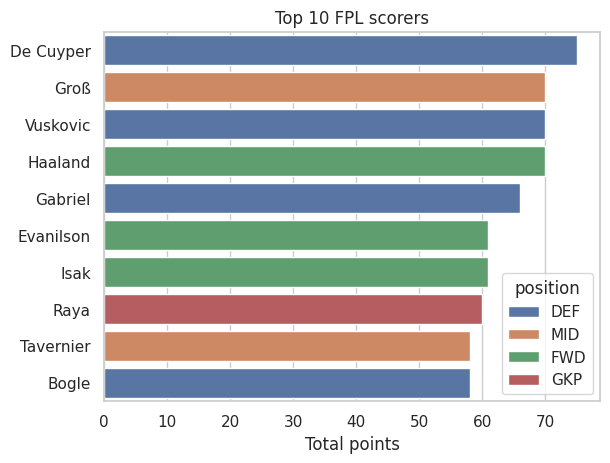

In [55]:
top10 = df.nlargest(10, "total_points")

sns.barplot(data=top10, x="total_points", y="web_name", hue="position", dodge=False)
plt.title("Top 10 FPL scorers")
plt.xlabel("Total points")
plt.ylabel("")
plt.show()

**Do expensive players score more?**

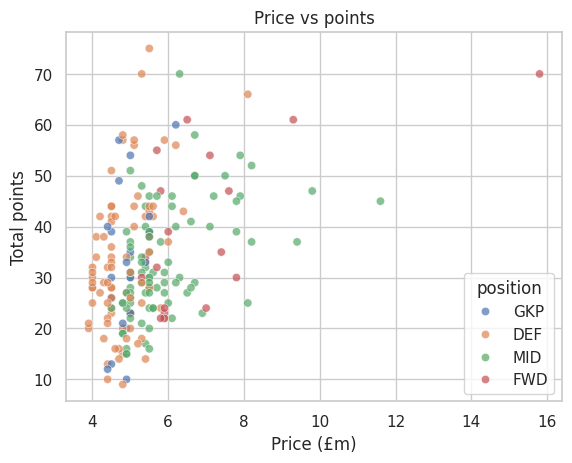

In [56]:
sns.scatterplot(data=df, x="price", y="total_points", hue="position", alpha=0.7)
plt.title("Price vs points")
plt.xlabel("Price (£m)")
plt.ylabel("Total points")
plt.show()

Mostly yes, but look at the spread. Plenty of cheap players outscore expensive ones. That's where value lives.

**Expected goals vs real goals**

Expected goals (xG) measures the quality of a player's chances. A player above the line is finishing better than expected. A player below it is missing chances, or getting unlucky.

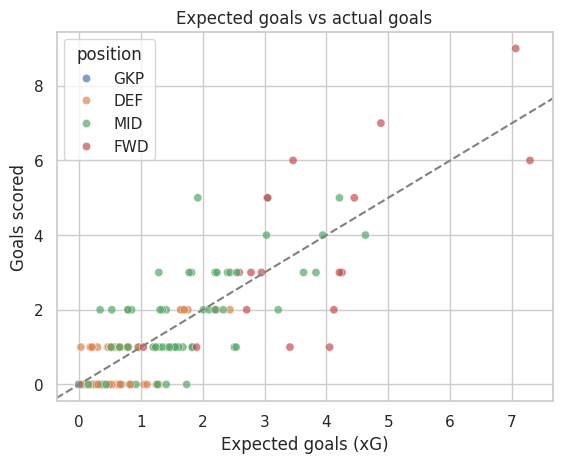

In [57]:
sns.scatterplot(data=df, x="expected_goals", y="goals_scored", hue="position", alpha=0.7)
plt.axline((0, 0), slope=1, color="grey", linestyle="--")
plt.title("Expected goals vs actual goals")
plt.xlabel("Expected goals (xG)")
plt.ylabel("Goals scored")
plt.show()

**Which positions score the most?**

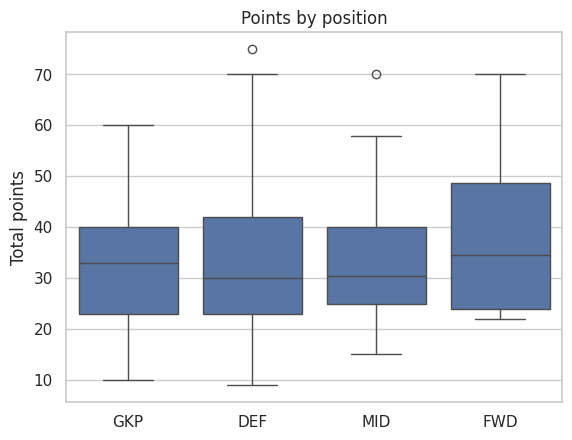

In [58]:
sns.boxplot(data=df, x="position", y="total_points", order=["GKP", "DEF", "MID", "FWD"])
plt.title("Points by position")
plt.xlabel("")
plt.ylabel("Total points")
plt.show()

## 6. Build a model

We want the model to learn: *given how a player has played, how many points should he have?*

So the inputs (**features**) are things that describe performance: minutes, chances created, chances taken, defending. We deliberately leave out actual goals and assists, because those are the "luck" part we want to measure.

The thing we predict (the **target**) is total points.

In [59]:
features = [
    "minutes", "starts", "price",
    "expected_goals", "expected_assists", "expected_goals_conceded","clean_sheets",

    "defensive_contribution",
]

X = pd.get_dummies(df[features + ["position"]], columns=["position"], dtype=int)
y = df["total_points"]

X.head()

,minutes,starts,price,expected_goals,expected_assists,expected_goals_conceded,clean_sheets,defensive_contribution,position_DEF,position_FWD,position_GKP,position_MID
0,900,10,6.2,0.00,0.01,7.59,7,0,0,0,1,0
1,900,10,8.1,1.47,0.25,7.59,7,91,1,0,0,0
2,767,9,5.9,1.22,1.01,6.93,6,42,1,0,0,0
3,532,7,5.4,0.18,0.83,2.84,4,28,1,0,0,0
4,596,7,9.4,3.63,1.20,5.10,4,46,0,0,0,1


We split the data. The model learns from 80% of players (the **training set**) and we test it on the 20% it has never seen (the **test set**). Like studying past questions, then sitting a real exam.

In [60]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

len(X_train), len(X_test)

(166, 42)

We try two models:

- **Linear regression**: draws the best straight-line relationship between features and points.
- **Random forest**: hundreds of small decision trees that vote. Can capture more complex patterns.

In [61]:
linear = LinearRegression().fit(X_train, y_train)
forest = RandomForestRegressor(n_estimators=300, random_state=42).fit(X_train, y_train)

## 7. Evaluate the model

Two scores:

- **MAE** (mean absolute error): on average, how many points is the prediction off by? Lower is better.
- **R²**: how much of the difference between players the model explains. 1 is perfect, 0 is useless.

We also compare to a lazy **baseline**: guess the average for everyone. A model that can't beat that is worthless.

In [62]:
baseline = [y_train.mean()] * len(y_test)

results = pd.DataFrame({
    "MAE": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, linear.predict(X_test)),
        mean_absolute_error(y_test, forest.predict(X_test)),
    ],
    "R²": [
        r2_score(y_test, baseline),
        r2_score(y_test, linear.predict(X_test)),
        r2_score(y_test, forest.predict(X_test)),
    ],
}, index=["Guess the average", "Linear regression", "Random forest"]).round(2)

results

,MAE,R²
Guess the average,9.78,-0.01
Linear regression,5.75,0.68
Random forest,6.53,0.51


Pick the model with the lower MAE. Let's see how its predictions compare to reality. Points on the line are perfect predictions.

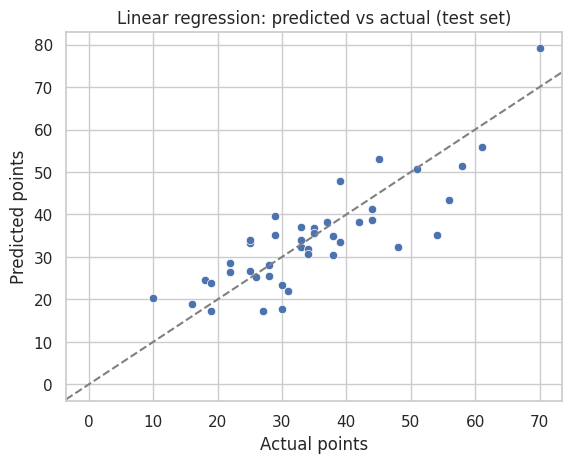

In [63]:
best_name = results["MAE"].iloc[1:].idxmin()
best_model = {"Linear regression": linear, "Random forest": forest}[best_name]

sns.scatterplot(x=y_test, y=best_model.predict(X_test))
plt.axline((0, 0), slope=1, color="grey", linestyle="--")
plt.title(f"{best_name}: predicted vs actual (test set)")
plt.xlabel("Actual points")
plt.ylabel("Predicted points")
plt.show()

**What does the random forest think matters most?**

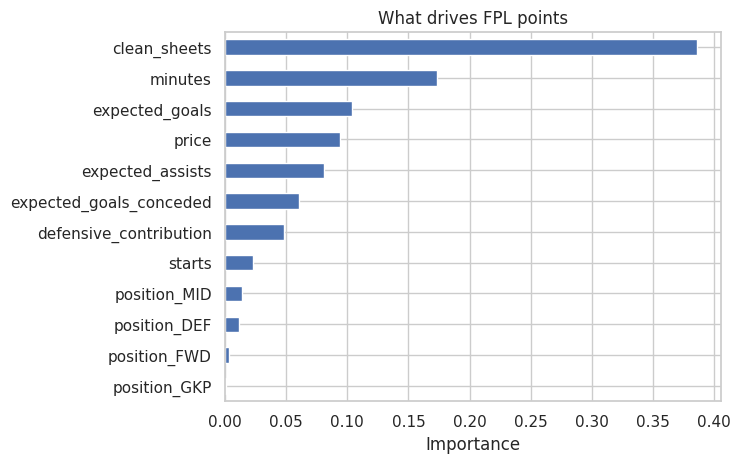

In [64]:
importance = pd.Series(forest.feature_importances_, index=X.columns).sort_values()

importance.plot(kind="barh")
plt.title("What drives FPL points")
plt.xlabel("Importance")
plt.show()

## 8. Use the model

Now we answer the question. Every player gets an **expected points** score. To keep it fair, each player's prediction comes from a model that never saw him during training (`cross_val_predict` handles this).

- `luck` below zero: fewer points than his performances deserve. **Buy candidate.**
- `luck` above zero: more points than he deserves. Could cool off.

In [65]:
df["expected_points"] = cross_val_predict(best_model, X, y, cv=5).round(1)
df["luck"] = (df["total_points"] - df["expected_points"]).round(1)

show = ["web_name", "team", "position", "price", "total_points", "expected_points", "luck", "selected_by_percent"]

**Unluckiest players: due some points**

In [66]:
df.nsmallest(10, "luck")[show]

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent
97,Gonzalo,Fulham,FWD,5.9,24,54.3,-30.3,3.6
94,Bobb,Fulham,MID,5.5,35,53.7,-18.7,0.5
37,Thiago,Brentford,FWD,7.8,30,48.1,-18.1,8.1
4,Saka,Arsenal,MID,9.4,37,50.8,-13.8,5.5
69,Henderson,Crystal Palace,GKP,4.9,10,23.3,-13.3,1.0
143,Barcola,Liverpool,MID,8.1,25,38.2,-13.2,4.4
70,Benitez,Crystal Palace,GKP,4.5,13,25.3,-12.3,0.1
172,Wissa,Newcastle,FWD,5.9,22,34.2,-12.2,8.3
96,King,Fulham,MID,5.5,39,50.6,-11.6,3.3
144,Enzo,Man City,MID,6.9,23,34.4,-11.4,3.6


**Luckiest players: might cool off**

In [67]:
df.nlargest(10, "luck")[show]

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent
58,João Pedro,Chelsea,FWD,7.6,47,24.7,22.3,31.7
153,Cherki,Man City,MID,7.9,54,32.7,21.3,33.5
42,De Cuyper,Brighton,DEF,5.5,75,56.6,18.4,47.8
8,Konsa,Arsenal,DEF,4.8,57,38.9,18.1,24.6
18,N.Jackson,Aston Villa,FWD,7.1,54,36.6,17.4,31.2
48,Vuskovic,Brighton,DEF,5.3,70,53.6,16.4,9.3
130,Trafford,Leeds,GKP,5.0,54,38.7,15.3,6.5
116,Emersonn,Ipswich Town,FWD,5.4,34,18.8,15.2,2.8
163,Cunha,Man Utd,MID,7.8,45,30.6,14.4,5.6
104,Belloumi,Hull City,MID,5.3,48,33.7,14.3,9.6


**Best value: expected points per £1m, available players only**

In [68]:
df["value"] = (df["expected_points"] / df["price"]).round(1)

(df[df["status"] == "a"]
   .sort_values("value", ascending=False)
   .groupby("position")
   .head(3)
   .sort_values(["position", "value"], ascending=[True, False])
   [show + ["value"]])

,web_name,team,position,price,total_points,expected_points,luck,selected_by_percent,value
41,Boscagli,Brighton,DEF,4.5,44,47.1,-3.1,0.7,10.5
121,Bogle,Leeds,DEF,4.8,58,49.9,8.1,11.2,10.4
42,De Cuyper,Brighton,DEF,5.5,75,56.6,18.4,47.8,10.3
88,Barry,Everton,FWD,5.7,55,61.2,-6.2,10.7,10.7
97,Gonzalo,Fulham,FWD,5.9,24,54.3,-30.3,3.6,9.2
129,Calvert-Lewin,Leeds,FWD,6.0,39,49.7,-10.7,17.5,8.3
39,Verbruggen,Brighton,GKP,4.7,57,47.9,9.1,24.0,10.2
189,Kinsky,Spurs,GKP,4.4,40,38.2,1.8,15.6,8.7
0,Raya,Arsenal,GKP,6.2,60,49.2,10.8,47.5,7.9
94,Bobb,Fulham,MID,5.5,35,53.7,-18.7,0.5,9.8


## 9. Share the work

A finding that stays on your laptop helps nobody. Data scientists share:

- **A short summary** for non-technical people: "These 5 players are underpriced, here's why."
- **The code** on GitHub, so anyone can check it and rerun it.

**Save this notebook to GitHub from Colab:** `File` → `Save a copy in GitHub` → pick your repository → add a commit message → OK.

### Things to remember

- The data is **live**. Run this next week and the answers change.
- Expected points is not a promise. It says who *deserves* more, not who will get it.
- The model only knows what we gave it. No injuries, no fixtures, no form. Those are ideas for improving it.

### Try it yourself

1. Change the minutes filter from 270 to 450. Do the results change?
2. Add `"clean_sheets"` to the features. Does the MAE get better?
3. Find the best value goalkeeper under £5m.